<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm Strata Sun" width="260"></a>

<a href="https://query.farm/vgi/"><img src="assets/vgi-logo.png" alt="VGI logo" width="180"></a>

# Which lights would a brightness cap actually change?

A stored brightness setting is not the same as a lit, reachable lamp. We select only reachable lights that are already on, preview a cap inside a transaction, roll it back, and finally commit the same change. A separate attachment and an HTTP-write counter distinguish a staged view from the bridge’s state.

**Every device is synthetic.** The unchanged repository mock bridge runs on a disposable loopback server; the real Go worker talks to it through VGI. No real bridge, device key, discovery request or physical light is used. Updates affect only this local fixture, which resets on each run.

## One setting cap

`BRIGHTNESS_CAP` is an integer from **1 to 100**, in percentage points of the bridge’s brightness setting. Zero is excluded because it can turn a light off. We cap only lights that are on, reachable and above the value; all others remain unchanged. These settings do not measure power, energy or perceived light output. Restart and run all after editing.

In [1]:
BRIGHTNESS_CAP = 60  # percent setting, integer 1–100

In [2]:
import haybarn
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, display

from mock_bridge import MockBridge
from notebook_support import HaybarnSession, finish, theme

assert type(BRIGHTNESS_CAP) is int and 1 <= BRIGHTNESS_CAP <= 100
fixture = MockBridge()
bridge_url = fixture.url
native_connection = haybarn.connect()
connection = HaybarnSession(native_connection)
theme()
%load_ext sql
%config SqlMagic.autopandas = True
%config SqlMagic.autocommit = False
%config SqlMagic.feedback = False
%sql connection

Tip: You may define configurations in /Users/rusty/Development/notebook-rollout/full-rollout/checkouts/vgi-hue-go/notebooks/pyproject.toml or /Users/rusty/.jupysql/config.

Did not find user configurations in /Users/rusty/Development/notebook-rollout/full-rollout/checkouts/vgi-hue-go/notebooks/pyproject.toml.

## Connect a transactional view and an independent observer

Both literal locations fetch and cache the exact public Git revision with Go 1.27.4. There is no local checkout dependency. Setup disables device discovery, clears inherited Hue settings and uses disposable transaction storage. The visible bridge option points to loopback and the application key is a dummy accepted only by the fixture.

The small notebook adapter keeps one native Haybarn session, and JupySQL automatic commits are disabled. This preserves the meaning of the explicit SQL transaction statements below. Neither helper changes worker SQL or results.

In [3]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'hue' AS tx (TYPE vgi, LOCATION 'uv run --frozen --project . python github_go_worker.py Query-farm/vgi-hue-go c8edf307c8d5bceae8d66c5d2184ff7dec2f5097 ./cmd/vgi-hue-worker go1.27.4',
  bridge '{{bridge_url}}', app_key 'notebook-test-key', transactional true);
ATTACH 'hue' AS observer (TYPE vgi, LOCATION 'uv run --frozen --project . python github_go_worker.py Query-farm/vgi-hue-go c8edf307c8d5bceae8d66c5d2184ff7dec2f5097 ./cmd/vgi-hue-worker go1.27.4',
  bridge '{{bridge_url}}', app_key 'notebook-test-key');
CREATE TABLE initial AS
SELECT light_id, name, room, is_on, reachable, brightness FROM observer.main.lights;
CREATE TABLE policy AS
SELECT *, is_on AND reachable AND brightness > {{BRIGHTNESS_CAP}} AS selected,
       CASE WHEN is_on AND reachable AND brightness > {{BRIGHTNESS_CAP}}
            THEN {{BRIGHTNESS_CAP}} ELSE brightness END AS planned_brightness,
       CASE WHEN NOT reachable THEN 'Unreachable'
            WHEN NOT is_on THEN 'Off'
            WHEN brightness <= {{BRIGHTNESS_CAP}} THEN 'Already within cap'
            ELSE 'Cap selected' END AS reason
FROM initial;

,Count


In [4]:
%%sql plan <<
SELECT * FROM policy ORDER BY room, name;

,name,room,is_on,reachable,brightness,planned_brightness,reason
0,Hallway strip,Hallway,False,True,60.0,60.0,Off
1,Kitchen ceiling,Kitchen,True,True,80.0,60.0,Cap selected
2,Kitchen pendant,Kitchen,True,True,50.0,50.0,Already within cap
3,Desk lamp,Living room,True,False,100.0,100.0,Unreachable
4,Sofa lamp,Living room,False,True,30.0,30.0,Off


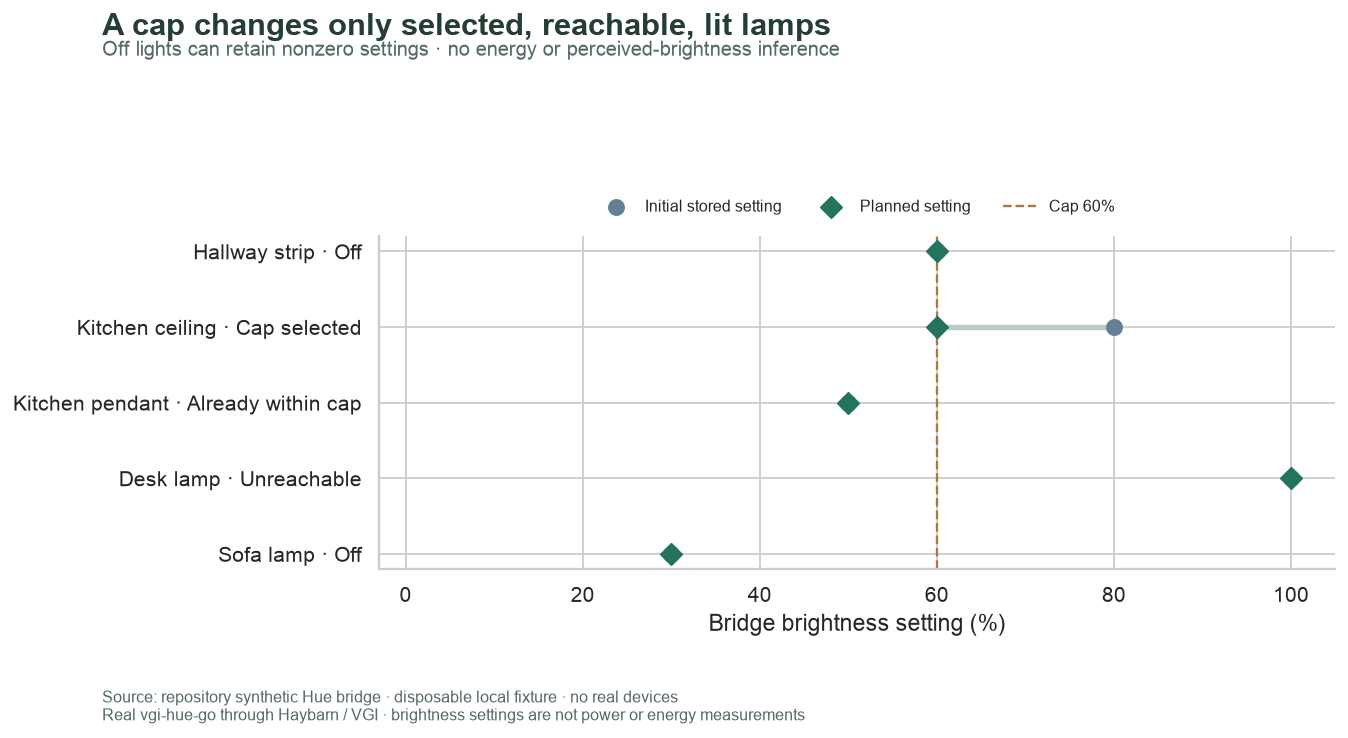

In [5]:
display(plan[["name", "room", "is_on", "reachable", "brightness", "planned_brightness", "reason"]])
fig, ax = plt.subplots(figsize=(11, 5.7))
y = np.arange(len(plan))
ax.hlines(y, plan.planned_brightness, plan.brightness, color="#bdc8c1", lw=3)
ax.scatter(plan.brightness, y, color="#647f96", s=70, label="Initial stored setting", zorder=3)
ax.scatter(plan.planned_brightness, y, color="#24735f", s=70, marker="D", label="Planned setting", zorder=3)
ax.axvline(BRIGHTNESS_CAP, color="#ad793b", ls="--", lw=1.3, label=f"Cap {BRIGHTNESS_CAP}%")
ax.set_yticks(y, [f"{r.name} · {r.reason}" for r in plan.itertuples()])
ax.invert_yaxis()
ax.set_xlim(-3, 105)
ax.set_xlabel("Bridge brightness setting (%)")
ax.set_ylabel("")
ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1.02), ncol=3, fontsize=9, frameon=False)
finish(
    fig,
    f"plan-cap-{BRIGHTNESS_CAP}",
    "A cap changes only selected, reachable, lit lamps",
    "Off lights can retain nonzero settings · no energy or perceived-brightness inference",
)

In [6]:
selected_count = int(plan.selected.sum())
display(
    Markdown(
        f"The cap selects **{selected_count} of {len(plan)} lights**. "
        "Off and unreachable lights retain their stored settings, even when those settings exceed the cap. "
        "The next step checks what a pending update looks like through two attachments."
    )
)

The cap selects **1 of 5 lights**. Off and unreachable lights retain their stored settings, even when those settings exceed the cap. The next step checks what a pending update looks like through two attachments.

## Preview the update without sending it to the bridge

`UPDATE` is a standalone statement and is never captured as a DataFrame, so display cannot repeat it. Inside this transaction the preview is a read-only SELECT: Haybarn permits writes to only one catalog per transaction, so the notebook does not create local tables here. Initial and final API snapshots are materialized outside the transaction.

In [7]:
%%sql
BEGIN;
UPDATE tx.main.lights SET brightness = {{BRIGHTNESS_CAP}}
WHERE is_on AND reachable AND brightness > {{BRIGHTNESS_CAP}};

,Count


In [8]:
%%sql staged <<
SELECT p.light_id, p.name, p.brightness AS initial_brightness, p.planned_brightness,
       t.brightness AS staged_brightness, o.brightness AS observer_brightness,
       abs(t.brightness-p.planned_brightness)<1e-9 AS preview_matches_plan,
       abs(o.brightness-p.brightness)<1e-9 AS bridge_still_initial,
       t.is_on=p.is_on AND o.is_on=p.is_on AS power_unchanged
FROM policy p JOIN tx.main.lights t USING(light_id) JOIN observer.main.lights o USING(light_id)
ORDER BY p.room, p.name;

In [9]:
display(staged)
assert staged.preview_matches_plan.all()
assert staged.bridge_still_initial.all()
assert staged.power_unchanged.all()
assert len(fixture.put_paths) == 0
puts_before_rollback = len(fixture.put_paths)
display(
    Markdown(
        f"The transaction preview matches the plan, while the observer still sees the initial settings. "
        f"Actual PUT requests to the synthetic bridge so far: **{puts_before_rollback}**."
    )
)

,light_id,name,initial_brightness,planned_brightness,staged_brightness,observer_brightness,preview_matches_plan,bridge_still_initial,power_unchanged
0,l-strip,Hallway strip,60.0,60.0,60.0,60.0,True,True,True
1,l-ceiling,Kitchen ceiling,80.0,60.0,60.0,80.0,True,True,True
2,l-pendant,Kitchen pendant,50.0,50.0,50.0,50.0,True,True,True
3,l-desk,Desk lamp,100.0,100.0,100.0,100.0,True,True,True
4,l-sofa,Sofa lamp,30.0,30.0,30.0,30.0,True,True,True


The transaction preview matches the plan, while the observer still sees the initial settings. Actual PUT requests to the synthetic bridge so far: **0**.

## Roll back, check the bridge, then commit a fresh transaction

Rollback discards the staged update. After proving that the observer remains unchanged, we repeat the same bounded update and explicitly commit it. This demonstration writes only to the bundled mock server.

In [10]:
%%sql
ROLLBACK;
CREATE TABLE after_rollback AS
SELECT light_id, is_on, brightness FROM observer.main.lights;

,Count


In [11]:
%%sql rollback_check <<
SELECT count(*)=(SELECT count(*) FROM initial) AND
       bool_and(r.is_on=i.is_on AND abs(r.brightness-i.brightness)<1e-9) AS unchanged
FROM initial i JOIN after_rollback r USING(light_id);

In [12]:
assert rollback_check.unchanged.all()
assert len(fixture.put_paths) == 0
puts_after_rollback = len(fixture.put_paths)
display(
    Markdown(
        "Rollback leaves every observer setting and power state unchanged, "
        f"with **{puts_after_rollback} PUT requests**. Now the same plan is committed."
    )
)

Rollback leaves every observer setting and power state unchanged, with **0 PUT requests**. Now the same plan is committed.

In [13]:
%%sql
BEGIN;
UPDATE tx.main.lights SET brightness = {{BRIGHTNESS_CAP}}
WHERE is_on AND reachable AND brightness > {{BRIGHTNESS_CAP}};
COMMIT;
CREATE TABLE after_commit AS
SELECT light_id, name, room, is_on, reachable, brightness FROM observer.main.lights;
CREATE TABLE compared AS
SELECT p.*, r.brightness AS rollback_brightness, a.brightness AS committed_brightness,
       a.is_on AS committed_power, a.reachable AS committed_reachable,
       abs(a.brightness-p.brightness)>1e-9 AS changed
FROM policy p JOIN after_rollback r USING(light_id) JOIN after_commit a USING(light_id);

,Count


In [14]:
%%sql compared <<
SELECT * FROM compared ORDER BY room, name;

,name,selected,brightness,rollback_brightness,committed_brightness,changed
0,Hallway strip,False,60.0,60.0,60.0,False
1,Kitchen ceiling,True,80.0,80.0,60.0,True
2,Kitchen pendant,False,50.0,50.0,50.0,False
3,Desk lamp,False,100.0,100.0,100.0,False
4,Sofa lamp,False,30.0,30.0,30.0,False


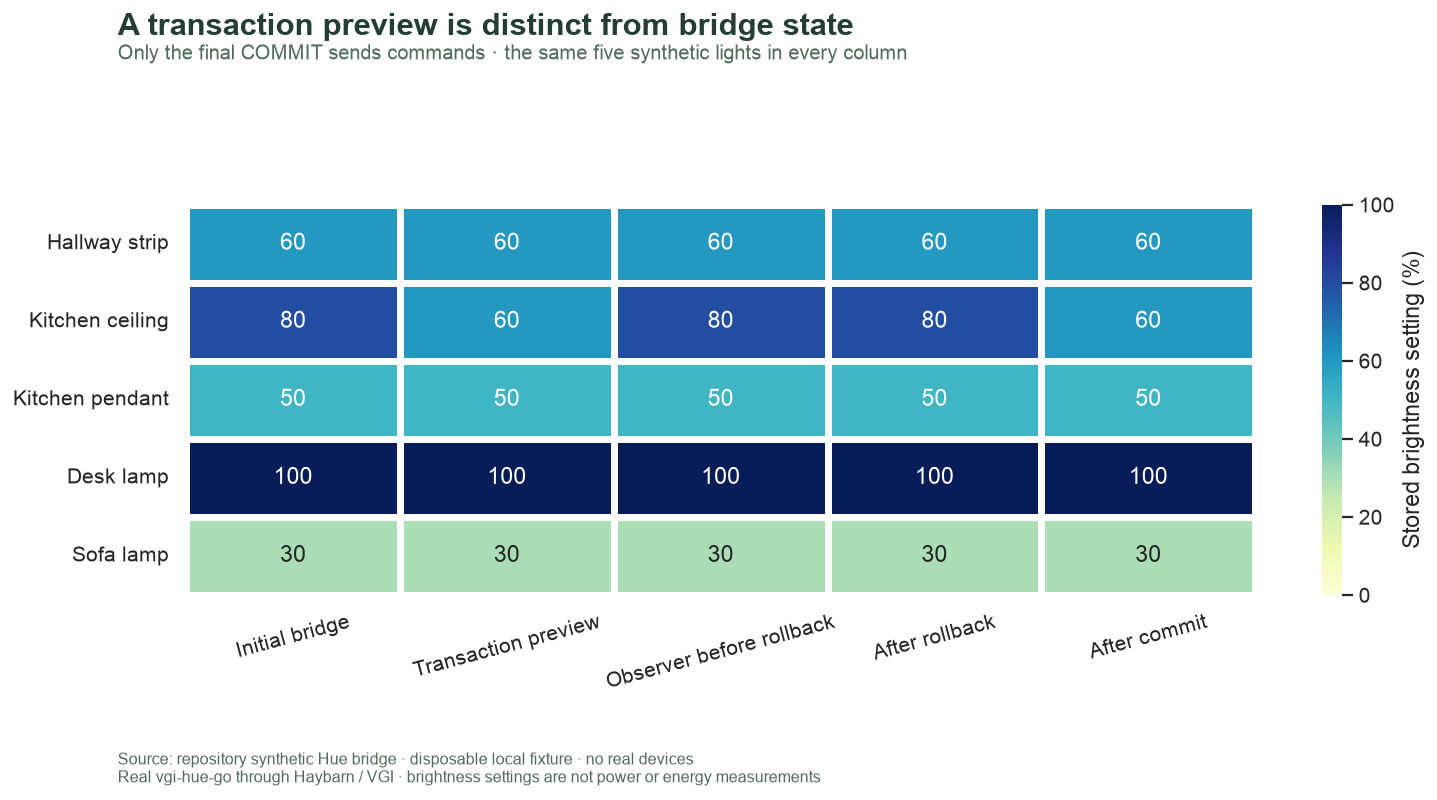

In [15]:
display(compared[["name", "selected", "brightness", "rollback_brightness", "committed_brightness", "changed"]])
view = compared.set_index("light_id")
staged_view = staged.set_index("light_id").loc[view.index]
plot = pd.DataFrame(
    {
        "Initial bridge": view.brightness,
        "Transaction preview": staged_view.staged_brightness,
        "Observer before rollback": staged_view.observer_brightness,
        "After rollback": view.rollback_brightness,
        "After commit": view.committed_brightness,
    },
    index=view.index,
)
fig, ax = plt.subplots(figsize=(12.5, 6.2))
sns.heatmap(
    plot,
    ax=ax,
    annot=True,
    fmt=".0f",
    vmin=0,
    vmax=100,
    cmap="YlGnBu",
    linewidths=3,
    linecolor="white",
    yticklabels=view.name.tolist(),
    cbar_kws={"label": "Stored brightness setting (%)"},
)
ax.set_xlabel("")
ax.set_ylabel("")
ax.tick_params(axis="x", rotation=15)
ax.tick_params(axis="y", rotation=0)
finish(
    fig,
    f"transaction-cap-{BRIGHTNESS_CAP}",
    "A transaction preview is distinct from bridge state",
    "Only the final COMMIT sends commands · the same five synthetic lights in every column",
)

## Reconcile the final state and command count

Check every light by its stable identifier, retain off and unreachable rows, and compare the actual write audit with the selected set. The mock is deterministic; a real bridge can fail, apply commands asynchronously or clamp values, so this example is not proof of atomic physical-device behavior.

In [16]:
%%sql checks <<
SELECT 'initial light IDs unique and nonempty' AS check_name,
 count(*)>0 AND count(*)=count(DISTINCT light_id) AS passed FROM initial
UNION ALL SELECT 'brightness input complete and bounded',bool_and(brightness IS NOT NULL AND brightness BETWEEN 0 AND 100) FROM initial
UNION ALL SELECT 'joined snapshots retain each light once',count(*)=(SELECT count(*) FROM initial)
 AND count(*)=count(DISTINCT light_id) FROM compared
UNION ALL SELECT 'committed settings match the plan',bool_and(abs(committed_brightness-planned_brightness)<1e-9) FROM compared
UNION ALL SELECT 'only selected lights changed',bool_and(changed=selected) FROM compared
UNION ALL SELECT 'power and reachability stay unchanged',bool_and(committed_power=is_on AND committed_reachable=reachable) FROM compared
UNION ALL SELECT 'unselected settings unchanged',coalesce(bool_and(abs(committed_brightness-brightness)<1e-9),true) FROM compared WHERE NOT selected;

In [17]:
display(checks)
assert checks.passed.all(), checks.loc[~checks.passed].to_dict("records")
assert len(fixture.put_paths) == selected_count
expected_paths = {f"/clip/v2/resource/light/{x}" for x in plan.loc[plan.selected, "light_id"]}
assert set(fixture.put_paths) == expected_paths
changed = int(compared.changed.sum())
display(
    Markdown(
        f"Final changed lights: **{changed} of {len(compared)}**. "
        f"Recorded PUT requests: **{len(fixture.put_paths)}**, exactly one per selected light, "
        "and none during the rolled-back preview. "
        f"All **{len(checks) + 8} state, preview, rollback and command checks** pass. "
        "This validates the local workflow without a physical-device action."
    )
)

,check_name,passed
0,initial light IDs unique and nonempty,True
1,brightness input complete and bounded,True
2,joined snapshots retain each light once,True
3,committed settings match the plan,True
4,only selected lights changed,True
5,power and reachability stay unchanged,True
6,unselected settings unchanged,True


Final changed lights: **1 of 5**. Recorded PUT requests: **1**, exactly one per selected light, and none during the rolled-back preview. All **15 state, preview, rollback and command checks** pass. This validates the local workflow without a physical-device action.

## Try one change

Change `BRIGHTNESS_CAP` from **60** to **30**, restart and run all. Predict whether the selected set grows and which lamps remain excluded. Compare the first chart, final changed count and actual PUT count. Each run starts from the same fresh synthetic bridge; it does not build on the previous run’s committed state. Power states, off/unreachable exclusions and rollback checks should remain unchanged. Restore **60** for the saved default.

In [18]:
connection.close()
fixture.close()

<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm Strata Sun" width="260"></a>